# Asignación de capital por RAROC: por qué el óptimo de un programa lineal no es de fiar

**Perfil:** Riesgo de crédito (estrategia y portafolio)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Asignar el presupuesto de crédito entre segmentos maximizando utilidad sujeta a capital suena a un programa lineal. ¿Qué falla cuando (i) el capital real no es lineal y (ii) los parámetros se **estiman** con ruido? ¿Qué corrección ayuda de verdad?

## Recorrido

1. Mundo verdadero: utilidad por segmento conocida y capital económico no lineal (diversificación entre segmentos).
2. **Versión 1:** programa lineal con cargos de capital por segmento (tangente en una cartera de referencia) y utilidades **estimadas**.
3. **Diagnóstico:** solución de esquina, capital real excedido, y sobreestimación de la utilidad (la "maldición del optimizador").
4. **Versión 2:** capital no lineal con covarianza estimada. **Versión 3:** más contracción (*shrinkage*) de las utilidades y asignación remuestreada.
5. Precios sombra, sensibilidad, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.optimize import linprog, minimize

## 2. El mundo verdadero

Ocho segmentos con utilidad esperada neta $\pi_i$ (margen − pérdida esperada − costo) por unidad de exposición. El **capital económico** de una cartera con pesos $x$ es
$$\mathrm{EC}(x)=z\sqrt{x^\top\Sigma x},\qquad z=3{,}09,$$
con $\Sigma$ la covarianza de pérdidas: los segmentos del mismo grupo (minorista, garantizado) están más correlacionados. Eso hace el capital **subaditivo**: diversificar reduce el capital total.

Problema verdadero: $\max_x\ \pi^\top x$ sujeto a $\sum x_i=1$, $0\le x_i\le 0{,}35$ y $\mathrm{EC}(x)\le K$.

In [2]:
SEGM = ["consumo", "tarjeta", "vehiculo", "hipotecario", "pyme", "corporativo", "microcredito", "leasing"]
N_S = len(SEGM)
PI = np.array([0.060, 0.115, 0.032, 0.018, 0.052, 0.014, 0.085, 0.034])        # utilidad neta verdadera por unidad de exposicion
SIG = np.array([0.020, 0.035, 0.012, 0.008, 0.028, 0.010, 0.040, 0.013])       # volatilidad de perdidas stand-alone
CORR = np.full((N_S, N_S), 0.25)
for grupo, r in (([0, 1, 6], 0.55), ([2, 3, 7], 0.45)):
    for a in grupo:
        for b in grupo: CORR[a, b] = r
np.fill_diagonal(CORR, 1.0)
SIGMA = np.outer(SIG, SIG) * CORR
assert np.all(np.linalg.eigvalsh(SIGMA) > 0)
Z = 3.09
CAP = 0.35

def ec(x, S=SIGMA):
    return Z * np.sqrt(x @ S @ x)

x_eq = np.full(N_S, 1 / N_S)
K = 0.80 * ec(x_eq)
print(f"EC(pesos iguales) = {ec(x_eq):.4f} | presupuesto de capital K = {K:.4f} (80% del anterior)")
print(f"Suma de EC stand-alone = {Z * SIG.sum() / N_S:.4f} vs EC diversificado = {ec(x_eq):.4f}: razon de diversificacion {ec(x_eq) / (Z * SIG.sum() / N_S):.2f}")

EC(pesos iguales) = 0.0426 | presupuesto de capital K = 0.0340 (80% del anterior)
Suma de EC stand-alone = 0.0641 vs EC diversificado = 0.0426: razon de diversificacion 0.66


In [3]:
def optimo_verdadero(pi=PI, S=SIGMA, presupuesto=K):
    cons = [{"type": "eq", "fun": lambda x: x.sum() - 1}, {"type": "ineq", "fun": lambda x: presupuesto - ec(x, S)}]
    mejor = None
    for x0 in (x_eq, np.r_[np.full(4, 0.2), np.full(4, 0.05)], np.r_[np.full(4, 0.05), np.full(4, 0.2)]):
        r = minimize(lambda x: -pi @ x, x0, bounds=[(0, CAP)] * N_S, constraints=cons, method="SLSQP", options={"maxiter": 500, "ftol": 1e-12})
        if r.success and ec(r.x, S) <= presupuesto * (1 + 1e-6) and (mejor is None or -r.fun > mejor[0]): mejor = (-r.fun, r.x)
    return mejor

U_OPT, X_OPT = optimo_verdadero()
RAROC_OPT = U_OPT / K            # utilidad por unidad de capital VERDADERO del optimo (usa todo el presupuesto)
print(f"Utilidad del optimo verdadero = {U_OPT:.5f} | capital usado = {ec(X_OPT):.4f} (K = {K:.4f}) | RAROC del optimo = {RAROC_OPT:.4f}")
pd.DataFrame({"x_optimo": X_OPT, "PI": PI, "sigma": SIG}, index=SEGM).round(4)

Utilidad del optimo verdadero = 0.04568 | capital usado = 0.0340 (K = 0.0340) | RAROC del optimo = 1.3419


,x_optimo,PI,sigma
consumo,0.1619,0.0600,0.0200
tarjeta,0.1303,0.1150,0.0350
vehiculo,0.2540,0.0320,0.0120
hipotecario,0.1974,0.0180,0.0080
pyme,0.0392,0.0520,0.0280
corporativo,0.0062,0.0140,0.0100
microcredito,0.0000,0.0850,0.0400
leasing,0.2110,0.0340,0.0130


## 3. Versión 1: programa lineal con cargos de capital por segmento

Los modelos de asignación suelen **linealizar** el capital: se asigna a cada segmento un cargo $k_i$ por unidad de exposición (la contribución marginal a una cartera de referencia, aquí la de pesos iguales),
$$k_i=z\,\frac{(\Sigma x_{\text{ref}})_i}{\sqrt{x_{\text{ref}}^\top\Sigma x_{\text{ref}}}},$$
y se resuelve $\max\hat\pi^\top x$ sujeto a $k^\top x\le K$. Las utilidades $\hat\pi_i$ **no se conocen**: se estiman con ruido.

In [4]:
S_PI = 0.012                                        # desvio de estimacion de cada utilidad (del orden de las diferencias entre segmentos)

def cargos_lineales(S, xref=x_eq):
    return Z * (S @ xref) / np.sqrt(xref @ S @ xref)

def resolver_lp(pi_hat, k, presupuesto=K):
    r = linprog(-pi_hat, A_ub=[k], b_ub=[presupuesto], A_eq=[np.ones(N_S)], b_eq=[1], bounds=[(0, CAP)] * N_S, method="highs")
    return r

K_LIN = cargos_lineales(SIGMA)
assert abs(K_LIN @ x_eq - ec(x_eq)) < 1e-12, "el cargo lineal debe reproducir el capital en la cartera de referencia"

# una realizacion
rg = np.random.default_rng(1)
pi_hat = PI + rg.normal(0, S_PI, N_S)
lp = resolver_lp(pi_hat, K_LIN)
x_lp = lp.x
resumen = pd.DataFrame({"x_LP": x_lp, "x_optimo": X_OPT, "pi_hat": pi_hat, "PI": PI}, index=SEGM)
print(f"LP: utilidad estimada = {pi_hat @ x_lp:.5f} | utilidad VERDADERA = {PI @ x_lp:.5f} | optimo verdadero = {U_OPT:.5f}")
print(f"LP: capital lineal usado = {K_LIN @ x_lp:.4f} (K={K:.4f}) | capital VERDADERO = {ec(x_lp):.4f}")
resumen.round(4)

LP: utilidad estimada = 0.05733 | utilidad VERDADERA = 0.05085 | optimo verdadero = 0.04568
LP: capital lineal usado = 0.0340 (K=0.0340) | capital VERDADERO = 0.0396


,x_LP,x_optimo,pi_hat,PI
consumo,0.0000,0.1619,0.0641,0.0600
tarjeta,0.2331,0.1303,0.1249,0.1150
vehiculo,0.3500,0.2540,0.0360,0.0320
hipotecario,0.0000,0.1974,0.0024,0.0180
pyme,0.0000,0.0392,0.0629,0.0520
corporativo,0.0669,0.0062,0.0194,0.0140
microcredito,0.0000,0.0000,0.0786,0.0850
leasing,0.3500,0.2110,0.0410,0.0340


In [5]:
activos = int((x_lp > 1e-6).sum()); en_borde = int(((x_lp < 1e-6) | (x_lp > CAP - 1e-6)).sum())
print("Lectura:")
print(f"  El LP deja {activos} segmentos activos de {N_S}; {en_borde} de {N_S} variables quedan EN EL BORDE (0 o tope {CAP}).")
print(f"  Un programa lineal con 2 restricciones (presupuesto y capital) tiene solucion en un vertice: a lo sumo 2 variables estan estrictamente entre sus cotas. Aqui: {N_S - en_borde}.")
print(f"  Capital verdadero de la asignacion del LP: {ec(x_lp):.4f} = {ec(x_lp) / K:.2f}x el presupuesto K.")

Lectura:
  El LP deja 4 segmentos activos de 8; 6 de 8 variables quedan EN EL BORDE (0 o tope 0.35).
  Un programa lineal con 2 restricciones (presupuesto y capital) tiene solucion en un vertice: a lo sumo 2 variables estan estrictamente entre sus cotas. Aqui: 2.
  Capital verdadero de la asignacion del LP: 0.0396 = 1.16x el presupuesto K.


## 4. Diagnóstico

### 4.1 La linealización subestima el capital lejos de la cartera de referencia

Como $\mathrm{EC}$ es convexa y homogénea de grado 1, su aproximación tangente en $x_{\text{ref}}$ **nunca la supera**: $k^\top x\le\mathrm{EC}(x)$ para todo $x$, con igualdad solo en $x_{\text{ref}}$ (y su múltiplos). Cuanto más se aleje la asignación de la referencia, más capital real se **omite**.

In [6]:
rg = np.random.default_rng(7)
brechas = []
for _ in range(2000):
    x = rg.dirichlet(np.ones(N_S) * 0.7)
    brechas.append(ec(x) - K_LIN @ x)
brechas = np.array(brechas)
print(f"Brecha EC(x) - k'x en 2000 carteras aleatorias: minimo {brechas.min():.2e} (debe ser >= 0), media {brechas.mean():.4f}, maximo {brechas.max():.4f}")
dist = lambda x: 0.5 * np.abs(x - x_eq).sum()
xs = [rg.dirichlet(np.ones(N_S) * a) for a in (50, 5, 1, 0.3) for _ in range(300)]
rel = pd.DataFrame({"distancia_a_referencia": [dist(x) for x in xs], "capital_omitido_%": [(ec(x) / (K_LIN @ x) - 1) * 100 for x in xs]})
print(f"Correlacion entre distancia a la referencia y capital omitido: {rel.corr().iloc[0, 1]:+.2f}")

Brecha EC(x) - k'x en 2000 carteras aleatorias: minimo 1.58e-04 (debe ser >= 0), media 0.0041, maximo 0.0247


Correlacion entre distancia a la referencia y capital omitido: +0.81


### 4.2 La maldición del optimizador

Si $\hat\pi_i=\pi_i+\varepsilon_i$, el optimizador **elige los segmentos cuyo ruido es favorable**. La utilidad que el modelo *cree* obtener, $\hat\pi^\top\hat x$, supera sistemáticamente la utilidad *verdadera* de la asignación, $\pi^\top\hat x$. Se mide repitiendo el experimento 200 veces.

In [7]:
def estimar_sigma(T, rg):
    datos = rg.multivariate_normal(np.zeros(N_S), SIGMA, T)
    return np.cov(datos.T)

def experimento_lp(R=200, seed=0, T=60):
    rg = np.random.default_rng(seed)
    filas = []
    for _ in range(R):
        pi_h = PI + rg.normal(0, S_PI, N_S)
        S_h = estimar_sigma(T, rg)
        k_h = cargos_lineales(S_h)
        r = resolver_lp(pi_h, k_h)
        if r.status != 0: continue
        x = r.x
        filas.append({"u_creida": pi_h @ x, "u_verdadera": PI @ x, "u_verd/optimo": PI @ x / U_OPT, "EC_verdadero/K": ec(x) / K,
                      "RAROC_rel": (PI @ x / ec(x)) / RAROC_OPT, "capital_creido/verdadero": (k_h @ x) / ec(x),
                      "activos": (x > 1e-6).sum(), "HHI": (x ** 2).sum(), "rotacion_vs_optimo": 0.5 * np.abs(x - X_OPT).sum()})
    return pd.DataFrame(filas)

res_lp = experimento_lp()
res_lp["sobreestimacion"] = res_lp["u_creida"] - res_lp["u_verdadera"]
res_lp.describe().loc[["mean", "std", "min", "max"]].round(4)

,u_creida,u_verdadera,u_verd/optimo,EC_verdadero/K,RAROC_rel,capital_creido/verdadero,activos,HHI,rotacion_vs_optimo,sobreestimacion
mean,0.0573,0.0509,1.1139,1.2161,0.9175,0.8325,3.8450,0.3077,0.4333,0.0064
std,0.0072,0.0058,0.1276,0.1384,0.0546,0.0914,0.3628,0.0163,0.1085,0.0056
min,0.0400,0.0330,0.7227,0.8568,0.6288,0.5718,3.0000,0.2900,0.2518,-0.0069
max,0.0805,0.0703,1.5393,1.7488,0.9868,1.1671,4.0000,0.3350,0.8021,0.0217


In [8]:
print("Lectura (LP, 200 replicas):")
print(f"  La utilidad creida supera a la verdadera en {res_lp['sobreestimacion'].mean():.5f} en promedio (el {(res_lp['sobreestimacion'] > 0).mean():.0%} de las veces), es decir {res_lp['sobreestimacion'].mean() / res_lp['u_verdadera'].mean():.0%} de la utilidad verdadera.")
print(f"  El capital verdadero supera el presupuesto en el {(res_lp['EC_verdadero/K'] > 1.05).mean():.0%} de las replicas por mas de 5% (media {res_lp['EC_verdadero/K'].mean():.2f}x K). El modelo cree usar {res_lp['capital_creido/verdadero'].mean():.2f} del capital que realmente usa.")
print(f"  OJO con la comparacion de utilidad: el LP 'obtiene' {res_lp['u_verd/optimo'].mean():.0%} de la utilidad del optimo verdadero, pero porque USA MAS CAPITAL del permitido. La comparacion justa es el RAROC (utilidad por unidad de capital VERDADERO): {res_lp['RAROC_rel'].mean():.1%} del RAROC del optimo.")
print(f"  Segmentos activos: {res_lp['activos'].mean():.1f} en promedio (el optimo verdadero usa {(X_OPT > 1e-6).sum()}); rotacion media frente al optimo verdadero: {res_lp['rotacion_vs_optimo'].mean():.2f}.")

Lectura (LP, 200 replicas):
  La utilidad creida supera a la verdadera en 0.00639 en promedio (el 86% de las veces), es decir 13% de la utilidad verdadera.
  El capital verdadero supera el presupuesto en el 90% de las replicas por mas de 5% (media 1.22x K). El modelo cree usar 0.83 del capital que realmente usa.
  OJO con la comparacion de utilidad: el LP 'obtiene' 111% de la utilidad del optimo verdadero, pero porque USA MAS CAPITAL del permitido. La comparacion justa es el RAROC (utilidad por unidad de capital VERDADERO): 91.7% del RAROC del optimo.
  Segmentos activos: 3.8 en promedio (el optimo verdadero usa 7); rotacion media frente al optimo verdadero: 0.43.


## 5. Versión 2: capital no lineal con covarianza estimada

Se resuelve el problema con la restricción **no lineal** $z\sqrt{x^\top\hat\Sigma x}\le K$ (se mantiene el ruido en $\hat\pi$ y se estima $\hat\Sigma$ con $T=60$ observaciones). Esto elimina el error de linealización y recupera la diversificación.

In [9]:
def resolver_nolineal(pi_h, S_h, presupuesto=K):
    cons = [{"type": "eq", "fun": lambda x: x.sum() - 1}, {"type": "ineq", "fun": lambda x: presupuesto - ec(x, S_h)}]
    mejor = None
    for x0 in (x_eq, np.r_[np.full(4, 0.2), np.full(4, 0.05)], np.r_[np.full(4, 0.05), np.full(4, 0.2)]):
        r = minimize(lambda x: -pi_h @ x, x0, bounds=[(0, CAP)] * N_S, constraints=cons, method="SLSQP", options={"maxiter": 300, "ftol": 1e-11})
        if r.success and ec(r.x, S_h) <= presupuesto * (1 + 1e-6) and (mejor is None or -r.fun > mejor[0]): mejor = (-r.fun, r.x)
    return None if mejor is None else mejor[1]

def metricas(x, pi_h, S_h=None, creido=None):
    ec_creido = creido if creido is not None else ec(x, S_h)
    return {"u_creida": pi_h @ x, "u_verdadera": PI @ x, "u_verd/optimo": PI @ x / U_OPT, "EC_verdadero/K": ec(x) / K,
            "RAROC_rel": (PI @ x / ec(x)) / RAROC_OPT, "capital_creido/verdadero": ec_creido / ec(x),
            "activos": (x > 1e-6).sum(), "HHI": (x ** 2).sum(), "rotacion_vs_optimo": 0.5 * np.abs(x - X_OPT).sum()}

def js_contraccion(pi_h, s2=S_PI ** 2):
    # estimador James-Stein de parte positiva, contrayendo hacia la media
    m = pi_h.mean(); d = pi_h - m
    tau = max(0.0, 1 - (len(pi_h) - 3) * s2 / (d ** 2).sum())
    return m + tau * d, tau

def js_hacia_riesgo(pi_h, s2=S_PI ** 2):
    # contrae los residuos respecto de la recta pi ~ a + b*sigma (prior riesgo-retorno): SI cambia la asignacion
    X = np.column_stack([np.ones(N_S), SIG]); beta = np.linalg.lstsq(X, pi_h, rcond=None)[0]
    ajuste = X @ beta; res = pi_h - ajuste
    tau = max(0.0, 1 - (N_S - 4) * s2 / (res ** 2).sum())
    return ajuste + tau * res, tau

# verificacion matematica: con sum(x)=1, la contraccion UNIFORME hacia la media no puede cambiar la asignacion del LP
rg_inv = np.random.default_rng(5)
inv_ok = True
for _ in range(50):
    ph = PI + rg_inv.normal(0, S_PI, N_S); pjs, _t = js_contraccion(ph)
    k_ = cargos_lineales(estimar_sigma(60, rg_inv))
    inv_ok &= bool(np.allclose(resolver_lp(ph, k_).x, resolver_lp(pjs, k_).x, atol=1e-9))
print(f"La contraccion uniforme de James-Stein deja IDENTICA la asignacion del LP en 50 de 50 casos: {inv_ok}")
print("Razon: con sum(x)=1, max pi'x es invariante a sumar una constante y a multiplicar por un escalar positivo (tau>0).")

def experimento_todos(R=120, seed=0, T=60, B=12):
    rg = np.random.default_rng(seed)
    filas = []; fallos = 0
    for _ in range(R):
        pi_h = PI + rg.normal(0, S_PI, N_S)
        S_h = estimar_sigma(T, rg)
        r_lp = resolver_lp(pi_h, cargos_lineales(S_h))
        x2 = resolver_nolineal(pi_h, S_h)
        pi_js, tau = js_contraccion(pi_h)
        x3 = resolver_nolineal(pi_js, S_h)
        pi_r, tau_r = js_hacia_riesgo(pi_h); x5 = resolver_nolineal(pi_r, S_h)
        # remuestreo (tipo Michaud): promediar asignaciones bajo perturbaciones de las entradas
        xs = []
        for _ in range(B):
            p_b = pi_h + rg.normal(0, S_PI, N_S); S_b = estimar_sigma(T, rg)
            xb = resolver_nolineal(p_b, S_b)
            if xb is not None: xs.append(xb)
        if r_lp.status != 0 or x2 is None or x3 is None or x5 is None or len(xs) < B // 2: fallos += 1; continue
        x4 = np.mean(xs, axis=0)
        k_h = cargos_lineales(S_h)
        for nombre, x, pe, cr in (("v1 LP", r_lp.x, pi_h, k_h @ r_lp.x), ("v2 no lineal", x2, pi_h, None), ("v3a contraccion uniforme", x3, pi_js, None), ("v3b contraccion a recta riesgo-retorno", x5, pi_r, None), ("v3c remuestreada", x4, pi_h, None)):
            filas.append({"metodo": nombre, **metricas(x, pe, S_h, cr), "tau": tau, "tau_riesgo": tau_r})
    return pd.DataFrame(filas), fallos

res_todos, fallos = experimento_todos()
res_todos["sobreestimacion"] = res_todos["u_creida"] - res_todos["u_verdadera"]
tabla = res_todos.groupby("metodo")[["RAROC_rel", "u_verd/optimo", "sobreestimacion", "EC_verdadero/K", "capital_creido/verdadero", "activos", "HHI", "rotacion_vs_optimo"]].mean()
tabla["viola_capital>5%"] = res_todos.groupby("metodo")["EC_verdadero/K"].apply(lambda s: (s > 1.05).mean() * 100)
print(f"Replicas validas: {len(res_todos) // 5} (descartadas por fallo del optimizador: {fallos})")
tabla.round(4)

La contraccion uniforme de James-Stein deja IDENTICA la asignacion del LP en 50 de 50 casos: True
Razon: con sum(x)=1, max pi'x es invariante a sumar una constante y a multiplicar por un escalar positivo (tau>0).


Replicas validas: 120 (descartadas por fallo del optimizador: 0)


,RAROC_rel,u_verd/optimo,sobreestimacion,EC_verdadero/K,capital_creido/verdadero,activos,HHI,rotacion_vs_optimo,viola_capital>5%
metodo,,,,,,,,,
v1 LP,0.9114,1.1194,0.0063,1.2303,0.8197,3.8583,0.3074,0.4389,94.1667
v2 no lineal,0.9444,1.0021,0.0057,1.0611,0.9482,5.7083,0.2477,0.3403,51.6667
v3a contraccion uniforme,0.9444,1.0021,0.0057,1.0611,0.9482,5.7083,0.2477,0.3403,51.6667
v3b contraccion a recta riesgo-retorno,0.9381,1.0036,0.0033,1.0704,0.9404,6.1083,0.2336,0.3433,54.1667
v3c remuestreada,0.9632,0.9783,0.0047,1.0157,0.9953,7.8500,0.1892,0.2503,8.3333


In [10]:
print("Lectura (promedios sobre replicas):")
for m_, f in tabla.iterrows():
    print(f"  {m_:30s}: RAROC {f['RAROC_rel']:.1%} del optimo | capital verdadero {f['EC_verdadero/K']:.2f}x K (>5% en {f['viola_capital>5%']:.0f}%) | el modelo cree usar {f['capital_creido/verdadero']:.2f} del real | sobreestimacion de utilidad {f['sobreestimacion']:+.5f} | activos {f['activos']:.1f} | rotacion {f['rotacion_vs_optimo']:.2f}")
print(f"  Factor de contraccion medio: hacia la media tau = {res_todos['tau'].mean():.2f} | hacia la recta riesgo-retorno tau = {res_todos['tau_riesgo'].mean():.2f}  (1 = sin contraccion)")
print(f"  v3a (uniforme) vs v2: diferencia de RAROC {(tabla.loc['v3a contraccion uniforme', 'RAROC_rel'] - tabla.loc['v2 no lineal', 'RAROC_rel']) * 100:+.2f} pts (esperado ~0: no cambia la asignacion). v3b vs v2: {(tabla.loc['v3b contraccion a recta riesgo-retorno', 'RAROC_rel'] - tabla.loc['v2 no lineal', 'RAROC_rel']) * 100:+.2f} pts.")
nl = tabla.loc["v2 no lineal"]
print(f"  Aun con la forma correcta del capital (v2), el modelo cree usar {nl['capital_creido/verdadero']:.2f} del capital real: el optimizador elige carteras donde la covarianza ESTIMADA subestima el riesgo (la maldicion del optimizador tambien actua sobre el riesgo).")

Lectura (promedios sobre replicas):
  v1 LP                         : RAROC 91.1% del optimo | capital verdadero 1.23x K (>5% en 94%) | el modelo cree usar 0.82 del real | sobreestimacion de utilidad +0.00631 | activos 3.9 | rotacion 0.44
  v2 no lineal                  : RAROC 94.4% del optimo | capital verdadero 1.06x K (>5% en 52%) | el modelo cree usar 0.95 del real | sobreestimacion de utilidad +0.00572 | activos 5.7 | rotacion 0.34
  v3a contraccion uniforme      : RAROC 94.4% del optimo | capital verdadero 1.06x K (>5% en 52%) | el modelo cree usar 0.95 del real | sobreestimacion de utilidad +0.00575 | activos 5.7 | rotacion 0.34
  v3b contraccion a recta riesgo-retorno: RAROC 93.8% del optimo | capital verdadero 1.07x K (>5% en 54%) | el modelo cree usar 0.94 del real | sobreestimacion de utilidad +0.00326 | activos 6.1 | rotacion 0.34
  v3c remuestreada              : RAROC 96.3% del optimo | capital verdadero 1.02x K (>5% en 8%) | el modelo cree usar 1.00 del real | sobreesti

### ¿Contraer mejora la **estimación** pero no la **decisión**?

El resultado anterior sugiere separar dos preguntas: (i) ¿la contracción reduce el error de las utilidades estimadas?, (ii) ¿ese error menor se traduce en una mejor asignación? Se mide la primera directamente.

In [11]:
rg_m = np.random.default_rng(99)
mse = {"sin contraer": [], "hacia la media": [], "hacia la recta riesgo-retorno": []}
for _ in range(600):
    ph = PI + rg_m.normal(0, S_PI, N_S)
    pj, _t = js_contraccion(ph); pr, _tr = js_hacia_riesgo(ph)
    mse["sin contraer"].append(((ph - PI) ** 2).mean()); mse["hacia la media"].append(((pj - PI) ** 2).mean()); mse["hacia la recta riesgo-retorno"].append(((pr - PI) ** 2).mean())
mse = pd.Series({k: np.mean(v) for k, v in mse.items()}, name="error_cuadratico_medio_de_pi")
tab_mse = pd.DataFrame({"error_cuadratico_medio": [f"{v:.3e}" for v in mse], "vs_sin_contraer_%": [f"{(v / mse['sin contraer'] - 1) * 100:+.1f}" for v in mse]}, index=mse.index)
print(tab_mse.to_string())
resid_verdadero = np.std(PI - np.column_stack([np.ones(N_S), SIG]) @ np.linalg.lstsq(np.column_stack([np.ones(N_S), SIG]), PI, rcond=None)[0])
print(f"Desvio de los residuos VERDADEROS alrededor de la recta riesgo-retorno: {resid_verdadero:.4f} (el ruido de estimacion es {S_PI}): no son ruido, es senal real.")

                              error_cuadratico_medio vs_sin_contraer_%
sin contraer                               1.436e-04              +0.0
hacia la media                             1.353e-04              -5.8
hacia la recta riesgo-retorno              1.212e-04             -15.6
Desvio de los residuos VERDADEROS alrededor de la recta riesgo-retorno: 0.0138 (el ruido de estimacion es 0.012): no son ruido, es senal real.


In [12]:
print("Lectura:")
print(f"  La contraccion hacia la media reduce el error cuadratico de las utilidades en {(1 - mse['hacia la media'] / mse['sin contraer']) * 100:.0f}% y hacia la recta riesgo-retorno en {(1 - mse['hacia la recta riesgo-retorno'] / mse['sin contraer']) * 100:.0f}%.")
print(f"  Pero el RAROC de la asignacion cambia en {(tabla.loc['v3a contraccion uniforme', 'RAROC_rel'] - tabla.loc['v2 no lineal', 'RAROC_rel']) * 100:+.2f} pts (uniforme) y {(tabla.loc['v3b contraccion a recta riesgo-retorno', 'RAROC_rel'] - tabla.loc['v2 no lineal', 'RAROC_rel']) * 100:+.2f} pts (recta).")
print("  Mejor estimacion no implica mejor decision: lo que importa para asignar es el ORDEN y las diferencias relativas entre segmentos, y contraer hacia un prior puede aplastar diferencias reales.")

Lectura:
  La contraccion hacia la media reduce el error cuadratico de las utilidades en 6% y hacia la recta riesgo-retorno en 16%.
  Pero el RAROC de la asignacion cambia en +0.00 pts (uniforme) y -0.63 pts (recta).
  Mejor estimacion no implica mejor decision: lo que importa para asignar es el ORDEN y las diferencias relativas entre segmentos, y contraer hacia un prior puede aplastar diferencias reales.


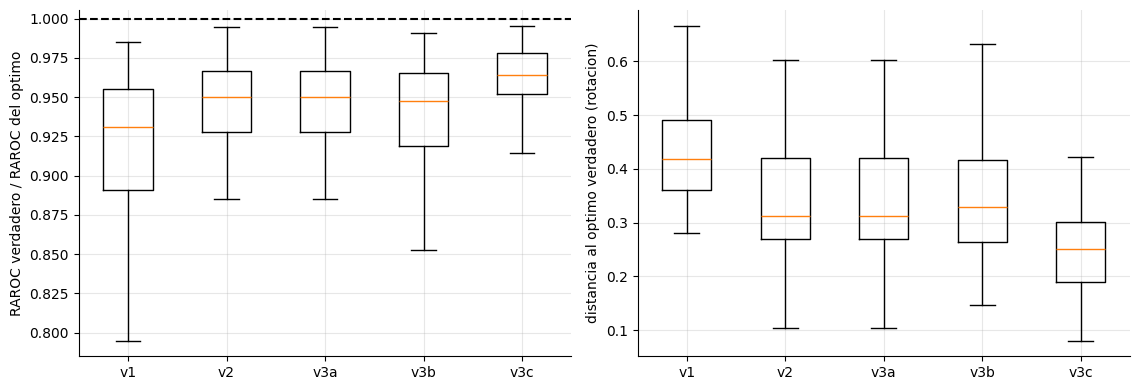

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
orden = ["v1 LP", "v2 no lineal", "v3a contraccion uniforme", "v3b contraccion a recta riesgo-retorno", "v3c remuestreada"]
ax[0].boxplot([res_todos[res_todos.metodo == m]["RAROC_rel"] for m in orden], labels=["v1", "v2", "v3a", "v3b", "v3c"], showfliers=False)
ax[0].set_ylabel("RAROC verdadero / RAROC del optimo"); ax[0].axhline(1, color="k", ls="--")
ax[1].boxplot([res_todos[res_todos.metodo == m]["rotacion_vs_optimo"] for m in orden], labels=["v1", "v2", "v3a", "v3b", "v3c"], showfliers=False)
ax[1].set_ylabel("distancia al optimo verdadero (rotacion)")
plt.tight_layout(); plt.show()

## 6. Precios sombra: ¿cuánto vale una unidad más de capital?

La solución del LP trae sus **multiplicadores duales**: el precio sombra del capital es el aumento de utilidad por una unidad más de presupuesto $K$. Se **verifica** con diferencias finitas, que es la forma correcta de confiar en un número que sale de un optimizador.

In [14]:
r0 = resolver_lp(PI, K_LIN, K)
precio_capital = -r0.ineqlin.marginals[0]
eps = 1e-4
u_mas = -resolver_lp(PI, K_LIN, K + eps).fun; u_menos = -resolver_lp(PI, K_LIN, K - eps).fun
dif_finita = (u_mas - u_menos) / (2 * eps)
print(f"Precio sombra del capital (dual del LP): {precio_capital:.4f}")
print(f"Diferencia finita d(utilidad)/dK:        {dif_finita:.4f}")
print(f"Interpretacion: una unidad mas de capital permitiria {precio_capital:.3f} unidades mas de utilidad (utilidad por unidad de capital marginal).")

Precio sombra del capital (dual del LP): 1.3397
Diferencia finita d(utilidad)/dK:        1.3397
Interpretacion: una unidad mas de capital permitiria 1.340 unidades mas de utilidad (utilidad por unidad de capital marginal).


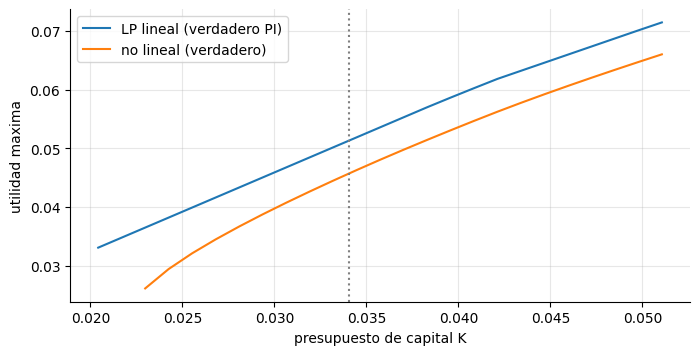

Lectura: con el presupuesto K=0.034, el LP lineal (con las utilidades verdaderas) promete 0.05129, un 12% mas que el maximo realmente alcanzable (0.04568).
  No es que el LP encuentre mejores carteras: su restriccion lineal subestima el capital real y por eso deja usar carteras que en realidad exceden K.


In [15]:
# curva de utilidad frente al presupuesto de capital: concava y lineal por tramos en el LP
Ks = np.linspace(0.6 * K, 1.5 * K, 25)
u_lp = [-(resolver_lp(PI, K_LIN, k_).fun) if resolver_lp(PI, K_LIN, k_).status == 0 else np.nan for k_ in Ks]
u_nl = [optimo_verdadero(presupuesto=k_)[0] if optimo_verdadero(presupuesto=k_) else np.nan for k_ in Ks]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(Ks, u_lp, label="LP lineal (verdadero PI)"); ax.plot(Ks, u_nl, label="no lineal (verdadero)"); ax.axvline(K, color="gray", ls=":")
ax.set_xlabel("presupuesto de capital K"); ax.set_ylabel("utilidad maxima"); ax.legend(); plt.show()
u_lp_K, u_nl_K = -resolver_lp(PI, K_LIN, K).fun, U_OPT
print(f"Lectura: con el presupuesto K={K:.3f}, el LP lineal (con las utilidades verdaderas) promete {u_lp_K:.5f}, un {(u_lp_K / u_nl_K - 1) * 100:.0f}% mas que el maximo realmente alcanzable ({u_nl_K:.5f}).")
print("  No es que el LP encuentre mejores carteras: su restriccion lineal subestima el capital real y por eso deja usar carteras que en realidad exceden K.")

## 7. Sensibilidad a la cantidad de datos y al ruido en las utilidades

In [16]:
filas = []
for s_pi in (0.004, 0.008, 0.012, 0.020):
    rg = np.random.default_rng(55)
    acum = {"v1": [], "v2": [], "v3a": [], "sobre_v1": [], "tau": []}
    for _ in range(80):
        pi_h = PI + rg.normal(0, s_pi, N_S); S_h = estimar_sigma(60, rg)
        r = resolver_lp(pi_h, cargos_lineales(S_h)); x2 = resolver_nolineal(pi_h, S_h)
        pi_js, tau = js_contraccion(pi_h, s_pi ** 2); x3 = resolver_nolineal(pi_js, S_h)
        pi_r, tau_r = js_hacia_riesgo(pi_h, s_pi ** 2); x5 = resolver_nolineal(pi_r, S_h)
        if r.status != 0 or x2 is None or x3 is None or x5 is None: continue
        raroc = lambda x: (PI @ x / ec(x)) / RAROC_OPT
        acum["v1"].append(raroc(r.x)); acum["v2"].append(raroc(x2)); acum["v3a"].append(raroc(x3)); acum.setdefault("v3b", []).append(raroc(x5)); acum.setdefault("tau_r", []).append(tau_r)
        acum["sobre_v1"].append(pi_h @ r.x - PI @ r.x); acum["tau"].append(tau)
    filas.append({"ruido_pi": s_pi, "tau_JS": np.mean(acum["tau"]), "RAROC v1 LP (%)": np.mean(acum["v1"]) * 100, "RAROC v2 no lineal (%)": np.mean(acum["v2"]) * 100,
                  "RAROC v3a contraccion uniforme (%)": np.mean(acum["v3a"]) * 100, "tau_riesgo": np.mean(acum["tau_r"]), "RAROC v3b a recta riesgo-retorno (%)": np.mean(acum["v3b"]) * 100, "sobreestimacion LP": np.mean(acum["sobre_v1"])})
sens = pd.DataFrame(filas).set_index("ruido_pi")
sens.round(4)

,tau_JS,RAROC v1 LP (%),RAROC v2 no lineal (%),RAROC v3a contraccion uniforme (%),tau_riesgo,RAROC v3b a recta riesgo-retorno (%),sobreestimacion LP
ruido_pi,,,,,,,
0.0040,0.9906,93.1789,96.3427,96.3427,0.9587,96.2622,0.0011
0.0080,0.9628,92.0994,95.0708,95.0708,0.8444,94.7710,0.0034
0.0120,0.9186,90.9738,94.0003,94.0003,0.6975,93.3309,0.0062
0.0200,0.7932,89.2394,92.1174,92.1174,0.4780,91.0642,0.0122


In [17]:
print("Lectura: al crecer el ruido de estimacion de las utilidades,")
print(f"  la sobreestimacion del LP sube de {sens['sobreestimacion LP'].iloc[0]:.5f} a {sens['sobreestimacion LP'].iloc[-1]:.5f}; el factor de contraccion cae de {sens['tau_JS'].iloc[0]:.2f} a {sens['tau_JS'].iloc[-1]:.2f}.")
print(f"  El RAROC del LP baja de {sens['RAROC v1 LP (%)'].iloc[0]:.1f}% a {sens['RAROC v1 LP (%)'].iloc[-1]:.1f}% del optimo; el del no lineal, de {sens['RAROC v2 no lineal (%)'].iloc[0]:.1f}% a {sens['RAROC v2 no lineal (%)'].iloc[-1]:.1f}%.")
da = sens["RAROC v3a contraccion uniforme (%)"] - sens["RAROC v2 no lineal (%)"]
db = sens["RAROC v3b a recta riesgo-retorno (%)"] - sens["RAROC v2 no lineal (%)"]
print(f"  La contraccion UNIFORME cambia el RAROC en {da.abs().max():.2f} pts como maximo (es un no-op para la asignacion).")
print(f"  La contraccion hacia la recta riesgo-retorno lo cambia en {db.iloc[0]:+.2f} pts con ruido bajo y {db.iloc[-1]:+.2f} pts con ruido alto.")

Lectura: al crecer el ruido de estimacion de las utilidades,
  la sobreestimacion del LP sube de 0.00109 a 0.01222; el factor de contraccion cae de 0.99 a 0.79.
  El RAROC del LP baja de 93.2% a 89.2% del optimo; el del no lineal, de 96.3% a 92.1%.
  La contraccion UNIFORME cambia el RAROC en 0.00 pts como maximo (es un no-op para la asignacion).
  La contraccion hacia la recta riesgo-retorno lo cambia en -0.08 pts con ruido bajo y -1.05 pts con ruido alto.


## 8. Pruebas automáticas

In [18]:
# 8.1 el cargo lineal reproduce el capital en la referencia y NUNCA lo supera fuera de ella (convexidad + homogeneidad)
assert abs(K_LIN @ x_eq - ec(x_eq)) < 1e-12
assert brechas.min() > -1e-12
# 8.2 subaditividad: el capital diversificado no supera la suma de capitales stand-alone
for _ in range(500):
    x = np.random.default_rng(_).dirichlet(np.ones(N_S))
    assert ec(x) <= Z * (SIG * x).sum() + 1e-12
# 8.3 el optimo verdadero es factible y ninguna cartera factible aleatoria lo supera
assert abs(X_OPT.sum() - 1) < 1e-8 and (X_OPT >= -1e-9).all() and (X_OPT <= CAP + 1e-9).all() and ec(X_OPT) <= K * (1 + 1e-6)
rg_ = np.random.default_rng(3)
mejor_aleatoria = max(PI @ x for x in (rg_.dirichlet(np.ones(N_S) * 0.8, 4000)) if x.max() <= CAP and ec(x) <= K)
assert mejor_aleatoria <= U_OPT + 1e-6
# 8.4 el LP es una solucion de vertice: a lo sumo 2 variables estrictamente entre sus cotas (2 restricciones)
assert (N_S - en_borde) <= 2
# 8.5 la maldicion del optimizador: la utilidad creida supera sistematicamente a la verdadera
assert res_lp["sobreestimacion"].mean() > 0 and (res_lp["sobreestimacion"] > 0).mean() > 0.75
# 8.6 la linealizacion deja el capital real por encima del presupuesto y el modelo cree usar menos de lo que usa
assert res_lp["EC_verdadero/K"].mean() > 1.1 and (res_lp["EC_verdadero/K"] > 1.05).mean() > 0.7
assert res_lp["capital_creido/verdadero"].mean() < 0.95
# 8.7 la utilidad sin respetar el capital engaña: el LP 'gana' en utilidad pero pierde en RAROC frente al no lineal
assert tabla.loc["v1 LP", "u_verd/optimo"] > tabla.loc["v2 no lineal", "u_verd/optimo"]
assert tabla.loc["v1 LP", "RAROC_rel"] < tabla.loc["v2 no lineal", "RAROC_rel"] < 1.0 + 1e-9
# 8.7b la maldicion tambien actua sobre el riesgo: aun con capital no lineal el modelo cree usar menos capital del real
assert tabla.loc["v2 no lineal", "capital_creido/verdadero"] < 1.0 and tabla.loc["v2 no lineal", "EC_verdadero/K"] > 1.0
# 8.8 las asignaciones remuestreadas son mas estables y menos concentradas, y acercan el capital real al presupuesto
rem, nl_ = tabla.loc["v3c remuestreada"], tabla.loc["v2 no lineal"]
assert rem["rotacion_vs_optimo"] < nl_["rotacion_vs_optimo"] and rem["HHI"] < nl_["HHI"]
assert rem["EC_verdadero/K"] < nl_["EC_verdadero/K"] and rem["RAROC_rel"] > nl_["RAROC_rel"]
# 8.9 la contraccion UNIFORME es un no-op para la asignacion (propiedad matematica), y su efecto medido es ~0
assert inv_ok
assert abs(tabla.loc["v3a contraccion uniforme", "RAROC_rel"] - tabla.loc["v2 no lineal", "RAROC_rel"]) < 0.002
assert (sens["RAROC v3a contraccion uniforme (%)"] - sens["RAROC v2 no lineal (%)"]).abs().max() < 0.2
# 8.9b la contraccion hacia la recta SI reduce el error de las utilidades y la sobreestimacion reportada, pero NO mejora la decision
assert mse["hacia la recta riesgo-retorno"] < mse["sin contraer"] and mse["hacia la media"] < mse["sin contraer"]
assert tabla.loc["v3b contraccion a recta riesgo-retorno", "sobreestimacion"] < tabla.loc["v2 no lineal", "sobreestimacion"]
assert tabla.loc["v3b contraccion a recta riesgo-retorno", "RAROC_rel"] <= tabla.loc["v2 no lineal", "RAROC_rel"] + 0.005
assert resid_verdadero > 0.8 * S_PI, "los residuos verdaderos no son despreciables frente al ruido: contraerlos pierde senal"
# 8.10 el precio sombra coincide con la diferencia finita
assert abs(precio_capital - dif_finita) < 1e-6 and precio_capital > 0
# 8.11 mas ruido en las utilidades implica mas sobreestimacion y peor RAROC
assert sens["sobreestimacion LP"].is_monotonic_increasing and sens["RAROC v1 LP (%)"].iloc[0] > sens["RAROC v1 LP (%)"].iloc[-1]
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: LP con cargos lineales | Solución de vértice (4 segmentos de 8); usa ≈1,22× el capital permitido pero cree usar 0,83×; la utilidad creída supera a la verdadera en ≈13 % | No fiarse de un LP con capital linealizado y utilidades estimadas |
| Métrica justa | En utilidad el LP parece ganar (111 % del óptimo) solo porque excede el capital; en RAROC verdadero queda en ≈91 % | Comparar métodos por RAROC o a igual capital real, nunca por utilidad sola |
| Linealización | La tangente subestima el capital real cuanto más lejos de la cartera de referencia (correlación +0,81 con la distancia) | Usar la forma no lineal o re-linealizar en el óptimo |
| v2: capital no lineal | RAROC ≈94 % del óptimo, pero aún usa ≈1,06× el capital: la maldición del optimizador actúa también sobre la covarianza estimada | No fiarse de la covarianza estimada en el punto elegido por el optimizador |
| v3a: contracción uniforme | Es un no-op para la asignación (con Σx=1 el objetivo es invariante a constante y escala): efecto medido ≈0, aunque reduce el error cuadrático de las utilidades | No usar contracción hacia la media global como remedio de la asignación |
| v3b: contracción a la recta riesgo-retorno | Reduce el error de las utilidades y la sobreestimación reportada (0,0057 → 0,0033), pero no mejora el RAROC (−0,6 pts): los residuos verdaderos (sd 0,0138) son señal, no ruido | Mejor estimación no implica mejor decisión: medir el efecto en la decisión |
| v3c: remuestreo | Mejor RAROC (≈96 %), menor rotación y capital real ≈1,02× el presupuesto | Preferir asignaciones remuestreadas con insumos ruidosos |
| Precio sombra | El dual coincide con la diferencia finita | Verificar siempre un dual con una perturbación |

**Límites que no deben ocultarse**

- El capital económico se modela como volatilidad normal; con colas pesadas o dependencia de cola la subaditividad podría fallar.
- Las utilidades se estiman con ruido independiente y gaussiano; en la práctica el error de estimación está correlacionado entre segmentos.
- La relación riesgo-retorno que sirve de prior en v3b es una propiedad del generador (π ≈ 2,5σ); en la realidad habría que justificarla.
- La covarianza se estima con 60 observaciones; con menos datos el problema empeora, y con más, mejora.
- Se ignoran costos de transición entre carteras y restricciones comerciales reales.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.